# Gaussian Mixture Model Clustering

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

In [9]:
# Load and standardize the Iris features.
data = load_iris(as_frame=True)
X = data.data
y = data.target
X_scaled = StandardScaler().fit_transform(X)
print(f"Samples: {X_scaled.shape[0]}")
print(f"Features: {list(X.columns)}")
print(f"Known classes for evaluation: {list(data.target_names)}")

Samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Known classes for evaluation: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## Fit a Gaussian mixture

`predict` returns the most likely component for each sample. `predict_proba` returns the full responsibility matrix, preserving the uncertainty of soft clustering.

In [10]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    n_init=10,
    random_state=42,
)
labels = gmm.fit_predict(X_scaled)
responsibilities = gmm.predict_proba(X_scaled)
gmm_metrics = pd.Series(
    {
        "Silhouette score": silhouette_score(X_scaled, labels),
        "Adjusted Rand index": adjusted_rand_score(y, labels),
        "Average log-likelihood": gmm.score(X_scaled),
        "Total log-likelihood": gmm.score(X_scaled) * len(X_scaled),
        "Converged": gmm.converged_,
        "EM iterations": gmm.n_iter_,
    }
)
gmm_metrics.round(4)

,0
Silhouette score,0.374165
Adjusted Rand index,0.903874
Average log-likelihood,-1.936926
Total log-likelihood,-290.53896
Converged,True
EM iterations,19


In [11]:
# Inspect the learned mixture weights, means, and soft assignments.
component_summary = pd.DataFrame(
    gmm.means_,
    columns=X.columns,
)
component_summary.insert(0, "Component weight", gmm.weights_)
print("Learned component parameters:")
print(component_summary.round(3).to_string(index=False))

responsibility_table = pd.DataFrame(
    responsibilities[:10],
    columns=[f"Component {index}" for index in range(gmm.n_components)],
)
print("Responsibilities for the first ten samples:")
print(responsibility_table.round(4).to_string(index=False))

Learned component parameters:
 Component weight  sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
            0.301              0.089            -0.643              0.254             0.130
            0.333             -1.015             0.853             -1.305            -1.255
            0.366              0.852            -0.249              0.980             1.037
Responsibilities for the first ten samples:
 Component 0  Component 1  Component 2
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0
         0.0          1.0          0.0


## Select the number of components

The Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC) balance model fit with model complexity. Lower values are preferred.

In [12]:
component_counts = range(1, 8)
selection_rows = []

for component_count in component_counts:
    candidate = GaussianMixture(
        n_components=component_count,
        covariance_type="full",
        n_init=10,
        random_state=42,
    )
    candidate.fit(X_scaled)
    selection_rows.append(
        {
            "Components": component_count,
            "AIC": candidate.aic(X_scaled),
            "BIC": candidate.bic(X_scaled),
        }
    )
selection_table = pd.DataFrame(selection_rows).set_index("Components")
selection_table.round(2)

,AIC,BIC
Components,,
1,1008.52,1050.67
2,707.40,794.71
3,669.08,801.55
4,667.39,845.02
5,649.65,872.44
6,639.65,907.59
7,608.56,921.67


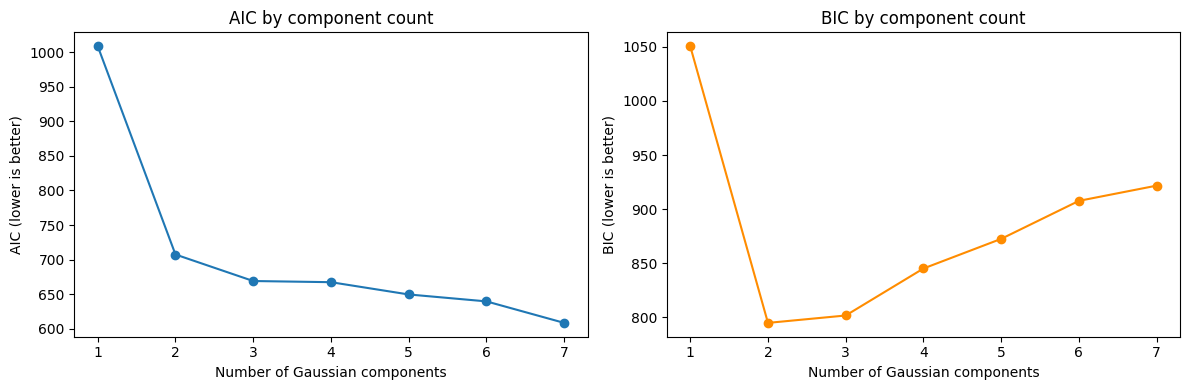

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(selection_table.index, selection_table["AIC"], marker="o")
axes[0].set_title("AIC by component count")
axes[0].set_xlabel("Number of Gaussian components")
axes[0].set_ylabel("AIC (lower is better)")
axes[1].plot(selection_table.index, selection_table["BIC"], marker="o", color="darkorange")
axes[1].set_title("BIC by component count")
axes[1].set_xlabel("Number of Gaussian components")
axes[1].set_ylabel("BIC (lower is better)")
plt.tight_layout()
plt.show()

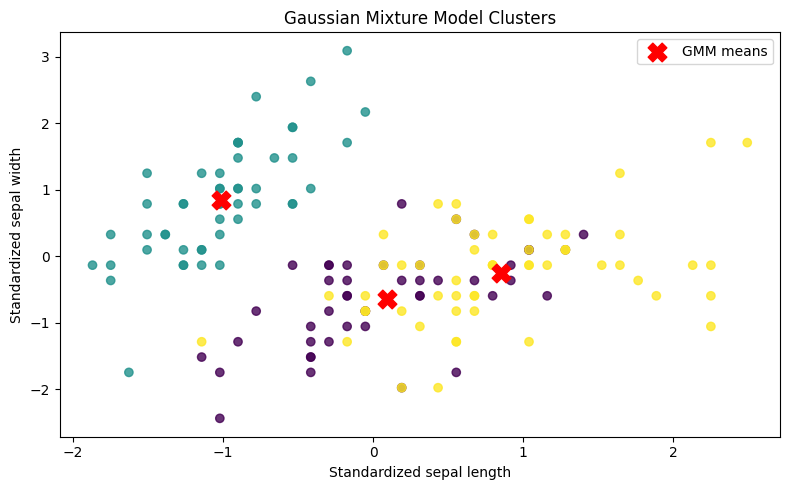

In [14]:
# Visualize the first two standardized features and GMM assignments.
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    alpha=0.8,
)
plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    marker="X",
    s=180,
    c="red",
    label="GMM means",
)
plt.xlabel("Standardized sepal length")
plt.ylabel("Standardized sepal width")
plt.title("Gaussian Mixture Model Clusters")
plt.legend()
plt.tight_layout()
plt.show()